### CRC cancer

In [2]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
import pandas as pd
import os

##### Fsocre

In [3]:
# 加载数据集
file_path = '../Fscore/CRC_sample_FscoreSorted_selected149.csv'
Fscoredata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [4]:
Fscoredata

,class,MOTIF_END_CAAA,MOTIF_END_CAAG,MOTIF_END_TGCC,MOTIF_END_CGCT,MOTIF_END_CAAC,MOTIF_END_TGCT,MOTIF_END_TGCA,MOTIF_END_GCCT,MOTIF_END_CAAT,...,flen_168,CNA_6:113000001-114000000,CNA_15:25000001-26000000,CNA_10:60000001-61000000,CNA_9:111000001-112000000,MOTIF_END_ACAG,GWFP_long_18:75000001-78077248,GWFP_total_6:165000001-170000000,TMD_58,GWFP_long_20:50000001-55000000
0,1,0.009949,0.006592,0.003104,0.000530,0.003667,0.004344,0.004948,0.003728,0.005559,...,0.024201,1.005210,0.986006,1.029920,0.911440,0.006535,-1.602360,0.629170,0.141962,0.989708
1,1,0.009502,0.006611,0.003125,0.000589,0.003445,0.004286,0.005072,0.003823,0.005277,...,0.026395,0.980233,1.076910,0.994043,0.920513,0.006378,-1.260290,1.124370,0.012048,0.639373
2,1,0.010231,0.006417,0.003003,0.000550,0.003593,0.004334,0.004904,0.003681,0.005649,...,0.024271,1.072270,1.003230,0.988853,1.064360,0.006396,-1.472770,0.567686,0.036517,1.436930
3,1,0.009809,0.006518,0.002948,0.000543,0.003582,0.004127,0.004887,0.003798,0.005513,...,0.026133,1.016910,1.040940,0.956403,0.967088,0.006554,-1.429920,0.915088,0.023508,0.596942
4,1,0.008984,0.006297,0.003269,0.000630,0.003529,0.004359,0.004997,0.004172,0.005091,...,0.023401,0.999808,1.132120,1.042400,0.846670,0.006420,-1.091970,1.039120,0.018829,0.304504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.009594,0.006362,0.003106,0.000624,0.003495,0.004239,0.004885,0.003643,0.005426,...,0.022045,1.025020,1.083210,0.976728,0.935836,0.006836,-1.322480,1.047360,0.017559,0.497925
314,0,0.008000,0.006294,0.003744,0.000899,0.003112,0.004837,0.005495,0.004871,0.004281,...,0.023335,0.834260,1.477170,1.161700,0.701231,0.006809,-0.443621,1.233080,0.033742,-0.137558
315,0,0.007920,0.006068,0.003533,0.000816,0.003305,0.004794,0.005441,0.004769,0.004458,...,0.023238,0.939090,1.284260,1.152280,0.825136,0.006268,-0.594346,1.362920,0.033058,0.027580
316,0,0.009064,0.006194,0.003404,0.000721,0.003418,0.004636,0.005172,0.004019,0.005089,...,0.021939,0.979172,1.124030,1.050850,0.917224,0.006765,-1.133690,0.935139,0.016563,0.351172


In [5]:
# 准备训练和测试集函数
def prepare_train_test_Fscore(data, cancer_type, output_dir):
    
    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Fscore/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [6]:
CRC_leaderboard_Fscore = prepare_train_test_Fscore(Fscoredata, "CRC cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       174.48 GB / 251.54 GB (69.4%)
Disk Space Avail:   8944.39 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [7]:
CRC_leaderboard_Fscore.to_csv("CRC_leaderboard_Fscore.csv", index=False)
CRC_leaderboard_Fscore

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.983398,0.937500,0.937500,0.875000,0.937500,0.937500,0.93750,0.983398,0.948540,roc_auc,3.362953,0.231233,19.599255,0.002157,0.000442,0.024067,2,True,5
1,WeightedEnsemble_BAG_L2,0.983398,0.921875,0.921875,0.844162,0.920635,0.935484,0.90625,0.983398,0.943270,roc_auc,3.410607,0.347987,21.018873,0.006824,0.009203,0.133101,2,True,10
2,NeuralNetFastAI_BAG_L1,0.981445,0.937500,0.937500,0.876714,0.939394,0.911765,0.96875,0.981445,0.942030,roc_auc,2.568981,0.153852,17.519889,2.568981,0.153852,17.519889,1,True,3
3,XGBoost_BAG_L1,0.979492,0.937500,0.937500,0.875000,0.937500,0.937500,0.93750,0.979492,0.912332,roc_auc,0.440700,0.066673,1.405219,0.440700,0.066673,1.405219,1,True,4
4,LightGBM_BAG_L2,0.979492,0.921875,0.921875,0.844162,0.923077,0.909091,0.93750,0.979492,0.937318,roc_auc,3.531119,0.347950,21.489110,0.127337,0.009166,0.603338,2,True,6
5,WeightedEnsemble_L3,0.979492,0.921875,0.921875,0.847483,0.925373,0.885714,0.96875,0.979492,0.958150,roc_auc,4.578774,0.589745,39.275995,0.002006,0.000457,0.067463,3,True,11
6,LightGBM_BAG_L1,0.976562,0.921875,0.921875,0.844162,0.923077,0.909091,0.93750,0.976562,0.920702,roc_auc,0.351115,0.010265,0.650079,0.351115,0.010265,0.650079,1,True,1
7,RandomForest_BAG_L2,0.974121,0.890625,0.890625,0.781632,0.892308,0.878788,0.90625,0.974121,0.924732,roc_auc,3.441357,0.449272,22.209930,0.037575,0.110488,1.324158,2,True,7
8,NeuralNetFastAI_BAG_L2,0.972656,0.921875,0.921875,0.844162,0.920635,0.935484,0.90625,0.972656,0.942340,roc_auc,4.298748,0.522238,37.868894,0.894965,0.183454,16.983122,2,True,8
9,RandomForest_BAG_L1,0.967285,0.875000,0.875000,0.755929,0.866667,0.928571,0.81250,0.967285,0.909759,roc_auc,0.042986,0.107993,1.310585,0.042986,0.107993,1.310585,1,True,2


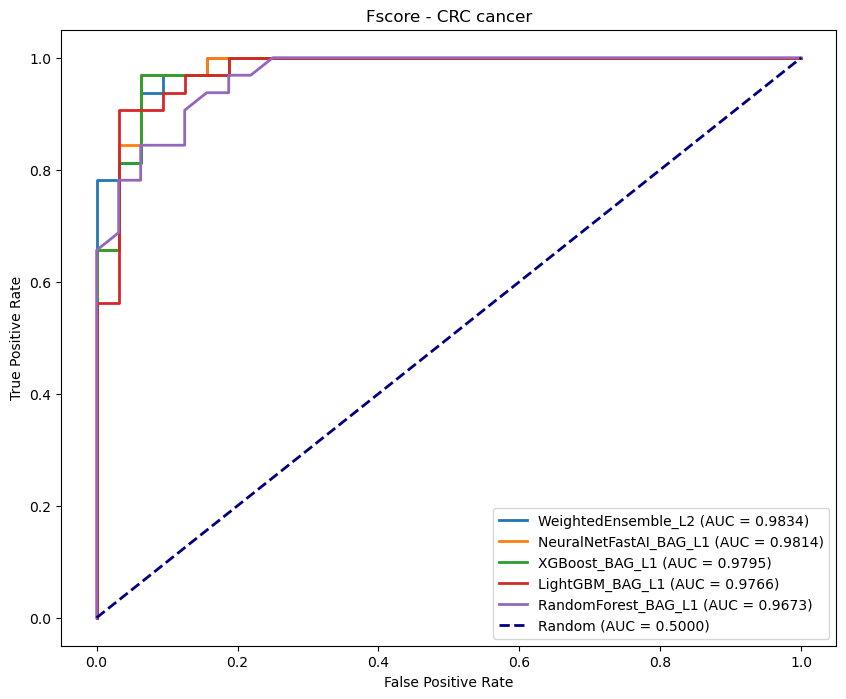

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

def plot_roc_curves_Fscore(data, model_dir):
    # 加载模型
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 
              'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 拆分数据集
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    y_true = test_data['class']
    
    # 收集各模型及Random的ROC数据
    roc_entries = []
    for model_name in models:
        model = predictor._trainer.load_model(model_name)
        y_prob = model.predict_proba(test_data)
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_entries.append((model_name, fpr, tpr, roc_auc))
    
    # 添加Random的ROC数据
    roc_entries.append(('Random', [0, 1], [0, 1], 0.5))
    
    # 按AUC降序排序
    roc_entries.sort(key=lambda x: x[3], reverse=True)
    
    # 绘制曲线
    plt.figure(figsize=(10, 8))
    for entry in roc_entries:
        name, fpr, tpr, auc_val = entry
        if name == 'Random':
            plt.plot(fpr, tpr, '--', color='navy', lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')
        else:
            plt.plot(fpr, tpr, lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Fscore - CRC cancer')
    plt.legend(loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Fscore'
data = Fscoredata 
plot_roc_curves_Fscore(data, model_dir)


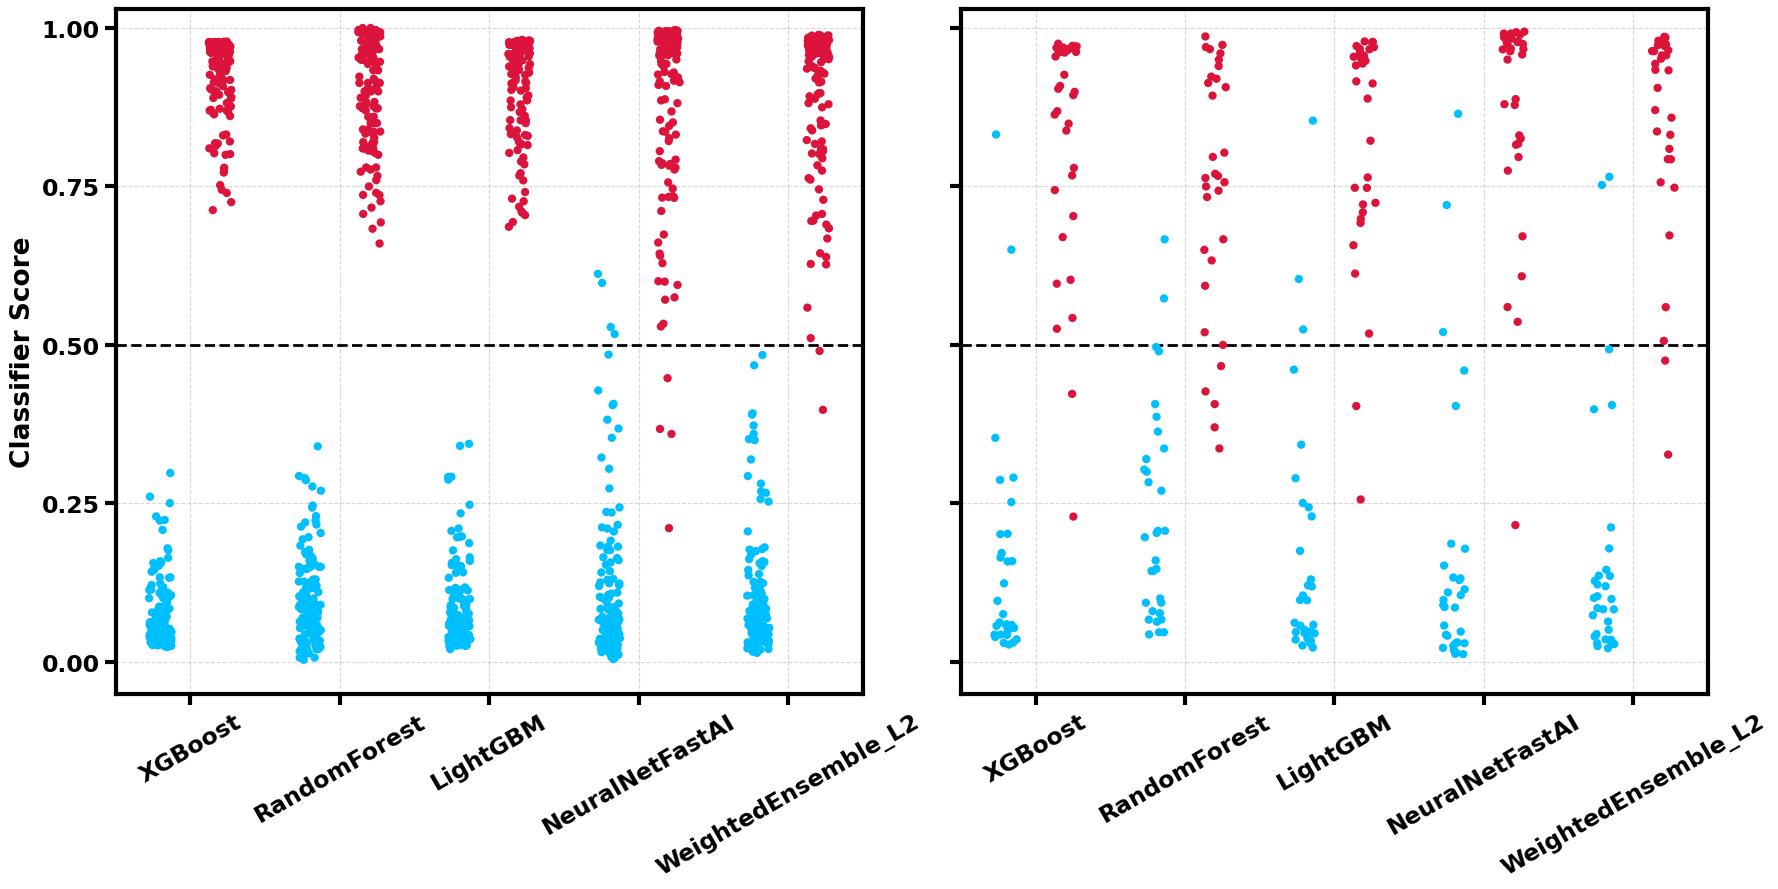

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split
from matplotlib.patches import Rectangle

def plot_classifier_scores_by_model(data, model_dir, output_dir='ScoreStripPlots'):
    predictor = TabularPredictor.load(model_dir)
    raw_models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 
                  'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

    # 显示名称，去掉后缀
    model_name_map = {m: m.replace('_BAG_L1', '') for m in raw_models}

    # 分层划分数据
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    
    sets = {
        'Train': train_data,
        'Test': test_data
    }

    output_path = os.path.join(model_dir, output_dir)
    os.makedirs(output_path, exist_ok=True)

    all_plot_data = []

    for model_name in raw_models:
        for set_name, df in sets.items():
            try:
                y_true = df['class']
                y_proba = predictor.predict_proba(df, model=model_name)
                y_score = y_proba.iloc[:, 1] if isinstance(y_proba, pd.DataFrame) else y_proba
                all_plot_data.extend([{
                    'Model': model_name_map[model_name],
                    'Score': score,
                    'TrueLabel': true_label,
                    'Set': set_name
                } for score, true_label in zip(y_score, y_true)])
            except Exception as e:
                print(f"Model {model_name} failed on {set_name}: {e}")

    plot_df = pd.DataFrame(all_plot_data)

    # 开始绘图
    fig, axes = plt.subplots(1, 2, figsize=(18, 9), sharey=True)
    for ax, set_name in zip(axes, ['Train', 'Test']):

        subset = plot_df[plot_df['Set'] == set_name]
        sns.stripplot(data=subset, x='Model', y='Score', hue='TrueLabel',
                      palette={0: 'deepskyblue', 1: 'crimson'},
                      dodge=True, jitter=0.15, size=6, ax=ax)

        ax.axhline(0.5, color='black', linestyle='--', linewidth=2)

        # ax.annotate(set_name, xy=(0.5, 1.054), xycoords='axes fraction',
        #     ha='center', va='top',
        #     fontsize=15, fontweight='bold',
        #     bbox=dict(facecolor='white', edgecolor='black', linewidth=1, boxstyle='square,pad=0.4'))

        ax.set_xlabel("")
        ax.tick_params(axis='x', labelsize=10, labelrotation=30)
        for label in ax.get_xticklabels():
            label.set_fontweight('bold')

        if set_name == 'Train':
            ax.set_ylabel("Classifier Score", fontsize=19, fontweight='bold')
        else:
            ax.set_ylabel("")

        ax.set_ylim(-0.05, 1.03)
        ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.tick_params(axis='x', rotation=30)

        # 去除图例
        ax.get_legend().remove()


        for spine in ax.spines.values():
            spine.set_linewidth(3)
        ax.tick_params(axis='both', width=3, length=8)
        for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
            tick_label.set_fontsize(17)
            tick_label.set_fontweight('bold')


    plt.tight_layout()
    plt.savefig(os.path.join(output_path, "ClassifierScore_ByModel.png"), dpi=300)
    plt.show()


# 调用
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Fscore'
data = Fscoredata
plot_classifier_scores_by_model(data, model_dir)


In [12]:
import os
import pandas as pd
import numpy as np
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

def compute_classifier_score_summary(data, model_dir, output_csv='ClassifierScore_Summary.csv'):
    # 加载模型
    predictor = TabularPredictor.load(model_dir)
    raw_models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1',
                  'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    model_name_map = {
        'XGBoost_BAG_L1': 'XGB',
        'RandomForest_BAG_L1': 'RF',
        'LightGBM_BAG_L1': 'LGB',
        'NeuralNetFastAI_BAG_L1': 'NN-FastAI',
        'WeightedEnsemble_L2': 'WE'
    }

    # 数据划分
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    sets = {
        'Train': train_data,
        'Test': test_data
    }

    rows = []

    for set_name, df in sets.items():
        y_true = df['class']
        for model in raw_models:
            try:
                y_score_df = predictor.predict_proba(df, model=model)
                y_score = y_score_df.iloc[:, 1] if isinstance(y_score_df, pd.DataFrame) else y_score_df

                mean_all = np.mean(y_score)
                mean_pos = np.mean(y_score[y_true == 1]) if any(y_true == 1) else np.nan

                rows.append({
                    'Set': set_name,
                    'Model': model_name_map[model],
                    'Mean_Score_All': round(mean_all, 4),
                    'Mean_Score_Positive': round(mean_pos, 4)
                })
            except Exception as e:
                print(f"{model} failed on {set_name}: {e}")
                rows.append({
                    'Set': set_name,
                    'Model': model_name_map[model],
                    'Mean_Score_All': np.nan,
                    'Mean_Score_Positive': np.nan
                })

    result_df = pd.DataFrame(rows)
    
    # 保存结果
    output_path = os.path.join(model_dir, output_csv)
    result_df.to_csv(output_path, index=False)
    print(f"Classifier score summary saved to: {output_path}")
    return result_df

# === 使用示例 ===
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Fscore'
data = Fscoredata  # <-- 请确保这个变量是 DataFrame 且有 'class' 列
summary_df = compute_classifier_score_summary(data, model_dir)


Classifier score summary saved to: /home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Fscore/ClassifierScore_Summary.csv


In [5]:
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 重新加载模型和数据
model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Fscore'
predictor = TabularPredictor.load(model_dir)
data = Fscoredata

# 模型名称列表
models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']

# 数据划分
train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)

# 用于保存结果
results = []

# 遍历每个模型并计算各项指标
for model_name in models:
    model = predictor._trainer.load_model(model_name)
    
    for set_name, df in [('Train', train_data), ('Test', test_data)]:
        y_true = df['class']
        y_proba = model.predict_proba(df)
        if isinstance(y_proba, pd.DataFrame):
            y_score = y_proba.iloc[:, 1]
        else:
            y_score = y_proba
        y_pred = (y_score >= 0.5).astype(int)

        results.append({
            'Model': model_name,
            'Set': set_name,
            'AUC': roc_auc_score(y_true, y_score),
            'Accuracy': accuracy_score(y_true, y_pred),
            'F1': f1_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred)
        })

# 转换为 DataFrame 展示
results_df = pd.DataFrame(results)
# 按 Test AUC 排序，仅保留 Test 行并根据 AUC 降序排列后提取顺序索引
test_auc_order = results_df[results_df['Set'] == 'Test'].sort_values(by='AUC', ascending=False)['Model']

# 按上述顺序重新排列整个结果 DataFrame（Validation 和 Test 行都保持）
results_df['Model'] = pd.Categorical(results_df['Model'], categories=test_auc_order, ordered=True)
results_df = results_df.sort_values(by=['Model', 'Set']).reset_index(drop=True)
results_df

,Model,Set,AUC,Accuracy,F1,Recall,Precision
0,WeightedEnsemble_L2,Test,0.983398,0.937500,0.937500,0.937500,0.937500
1,WeightedEnsemble_L2,Train,0.999876,0.992126,0.992063,0.984252,1.000000
2,NeuralNetFastAI_BAG_L1,Test,0.981445,0.937500,0.939394,0.968750,0.911765
3,NeuralNetFastAI_BAG_L1,Train,0.996528,0.968504,0.968504,0.968504,0.968504
4,XGBoost_BAG_L1,Test,0.979492,0.937500,0.937500,0.937500,0.937500
5,XGBoost_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
6,LightGBM_BAG_L1,Test,0.976562,0.921875,0.923077,0.937500,0.909091
7,LightGBM_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000
8,RandomForest_BAG_L1,Test,0.967285,0.890625,0.885246,0.843750,0.931034
9,RandomForest_BAG_L1,Train,1.000000,1.000000,1.000000,1.000000,1.000000


##### ANOVA

In [9]:
# 加载数据集
file_path = '../ANOVA/CRC_sample_AnovaSorted_selected149.csv'
ANOVAdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [10]:
ANOVAdata

,class,MOTIF_END_CAAA,MOTIF_END_CAAG,MOTIF_END_TGCC,MOTIF_END_CGCT,MOTIF_END_CAAC,MOTIF_END_TGCT,MOTIF_END_TGCA,MOTIF_END_GCCT,MOTIF_END_CAAT,...,flen_168,CNA_6:113000001-114000000,CNA_15:25000001-26000000,CNA_10:60000001-61000000,CNA_9:111000001-112000000,MOTIF_END_ACAG,GWFP_long_18:75000001-78077248,GWFP_total_6:165000001-170000000,TMD_58,GWFP_long_20:50000001-55000000
0,1,0.009949,0.006592,0.003104,0.000530,0.003667,0.004344,0.004948,0.003728,0.005559,...,0.024201,1.005210,0.986006,1.029920,0.911440,0.006535,-1.602360,0.629170,0.141962,0.989708
1,1,0.009502,0.006611,0.003125,0.000589,0.003445,0.004286,0.005072,0.003823,0.005277,...,0.026395,0.980233,1.076910,0.994043,0.920513,0.006378,-1.260290,1.124370,0.012048,0.639373
2,1,0.010231,0.006417,0.003003,0.000550,0.003593,0.004334,0.004904,0.003681,0.005649,...,0.024271,1.072270,1.003230,0.988853,1.064360,0.006396,-1.472770,0.567686,0.036517,1.436930
3,1,0.009809,0.006518,0.002948,0.000543,0.003582,0.004127,0.004887,0.003798,0.005513,...,0.026133,1.016910,1.040940,0.956403,0.967088,0.006554,-1.429920,0.915088,0.023508,0.596942
4,1,0.008984,0.006297,0.003269,0.000630,0.003529,0.004359,0.004997,0.004172,0.005091,...,0.023401,0.999808,1.132120,1.042400,0.846670,0.006420,-1.091970,1.039120,0.018829,0.304504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.009594,0.006362,0.003106,0.000624,0.003495,0.004239,0.004885,0.003643,0.005426,...,0.022045,1.025020,1.083210,0.976728,0.935836,0.006836,-1.322480,1.047360,0.017559,0.497925
314,0,0.008000,0.006294,0.003744,0.000899,0.003112,0.004837,0.005495,0.004871,0.004281,...,0.023335,0.834260,1.477170,1.161700,0.701231,0.006809,-0.443621,1.233080,0.033742,-0.137558
315,0,0.007920,0.006068,0.003533,0.000816,0.003305,0.004794,0.005441,0.004769,0.004458,...,0.023238,0.939090,1.284260,1.152280,0.825136,0.006268,-0.594346,1.362920,0.033058,0.027580
316,0,0.009064,0.006194,0.003404,0.000721,0.003418,0.004636,0.005172,0.004019,0.005089,...,0.021939,0.979172,1.124030,1.050850,0.917224,0.006765,-1.133690,0.935139,0.016563,0.351172


In [10]:
# 准备训练和测试集函数
def prepare_train_test_ANOVA(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ANOVA/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [11]:
CRC_leaderboard_ANOVA = prepare_train_test_ANOVA(ANOVAdata, "CRC cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       174.03 GB / 251.54 GB (69.2%)
Disk Space Avail:   8944.38 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0    NeuralNetFastAI_BAG_L1       0.909524   0.949431     roc_auc        2.297463       0.168211  22.426334                 2.297463                0.168211          22.426334            1       True          3
1    NeuralNetFastAI_BAG_L2       0.904762   0.942636     roc_auc        3.833727       0.528903  42.011720                 0.780630                0.154051          15.932943            2       True          8
2       WeightedEnsemble_L3       0.904762   0.962231     roc_auc        4.004300       0.548127  42.862172                 0.002120                0.000489           0.048165            3       True         11
3       WeightedEnsemble_L2       0.895238   0.956858     roc_auc        3.014436       0.272865  24.323822          

In [12]:
CRC_leaderboard_ANOVA.to_csv("CRC_leaderboard_ANOVA.csv", index=False)
CRC_leaderboard_ANOVA

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.983398,0.937500,0.937500,0.875000,0.937500,0.937500,0.93750,0.983398,0.948540,roc_auc,1.574553,0.270867,16.742522,0.002160,0.000453,0.029191,2,True,5
1,WeightedEnsemble_BAG_L2,0.983398,0.921875,0.921875,0.844162,0.920635,0.935484,0.90625,0.983398,0.943270,roc_auc,1.625639,0.388825,18.098797,0.006618,0.009467,0.249822,2,True,10
2,NeuralNetFastAI_BAG_L1,0.981445,0.937500,0.937500,0.876714,0.939394,0.911765,0.96875,0.981445,0.942030,roc_auc,1.093779,0.168742,14.439316,1.093779,0.168742,14.439316,1,True,3
3,XGBoost_BAG_L1,0.979492,0.937500,0.937500,0.875000,0.937500,0.937500,0.93750,0.979492,0.912332,roc_auc,0.299025,0.068893,1.477024,0.299025,0.068893,1.477024,1,True,4
4,LightGBM_BAG_L2,0.979492,0.921875,0.921875,0.844162,0.923077,0.909091,0.93750,0.979492,0.937318,roc_auc,1.775477,0.388432,18.496280,0.156456,0.009073,0.647305,2,True,6
5,WeightedEnsemble_L3,0.979492,0.921875,0.921875,0.847483,0.925373,0.885714,0.96875,0.979492,0.958150,roc_auc,2.878950,0.597884,34.013397,0.001725,0.000690,0.080757,3,True,11
6,LightGBM_BAG_L1,0.976562,0.921875,0.921875,0.844162,0.923077,0.909091,0.93750,0.976562,0.920702,roc_auc,0.179589,0.032778,0.796991,0.179589,0.032778,0.796991,1,True,1
7,RandomForest_BAG_L2,0.974121,0.890625,0.890625,0.781632,0.892308,0.878788,0.90625,0.974121,0.924732,roc_auc,1.659986,0.463155,18.983409,0.040964,0.083796,1.134434,2,True,7
8,NeuralNetFastAI_BAG_L2,0.972656,0.921875,0.921875,0.844162,0.920635,0.935484,0.90625,0.972656,0.942340,roc_auc,2.577634,0.534193,32.659111,0.958613,0.154835,14.810136,2,True,8
9,RandomForest_BAG_L1,0.967285,0.875000,0.875000,0.755929,0.866667,0.928571,0.81250,0.967285,0.909759,roc_auc,0.046629,0.108945,1.135644,0.046629,0.108945,1.135644,1,True,2


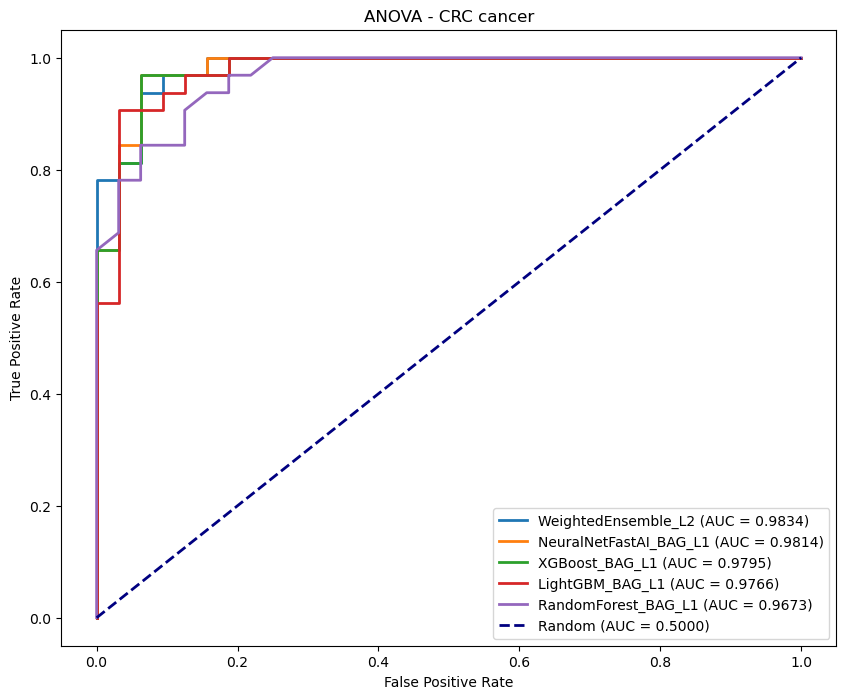

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ANOVA(data, model_dir):
    # 加载模型
    predictor = TabularPredictor.load(model_dir)
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 
              'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 拆分数据集
    train_data, test_data = train_test_split(data, test_size=0.2, stratify=data['class'], random_state=42)
    y_true = test_data['class']
    
    # 收集各模型及Random的ROC数据
    roc_entries = []
    for model_name in models:
        model = predictor._trainer.load_model(model_name)
        y_prob = model.predict_proba(test_data)
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_entries.append((model_name, fpr, tpr, roc_auc))
    
    # 添加Random的ROC数据
    roc_entries.append(('Random', [0, 1], [0, 1], 0.5))
    
    # 按AUC降序排序
    roc_entries.sort(key=lambda x: x[3], reverse=True)
    
    # 绘制曲线
    plt.figure(figsize=(10, 8))
    for entry in roc_entries:
        name, fpr, tpr, auc_val = entry
        if name == 'Random':
            plt.plot(fpr, tpr, '--', color='navy', lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')
        else:
            plt.plot(fpr, tpr, lw=2, 
                     label=f'{name} (AUC = {auc_val:.4f})')

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ANOVA - CRC cancer')
    plt.legend(loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()


model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/ANOVA'
data = ANOVAdata 
plot_roc_curves_ANOVA(data, model_dir)


##### ReliefF

In [7]:
# 加载数据集
file_path = '../ReliefF/CRC_sample_ReliefFSorted_selected34.csv'
ReliefFdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [8]:
ReliefFdata

,class,MOTIF_END_TGCC,MOTIF_END_TGCA,MOTIF_END_TGCT,MOTIF_END_TCCG,MOTIF_END_TGGT,MOTIF_END_CGCC,MOTIF_END_CGCT,MOTIF_END_GCCT,MOTIF_END_TCTG,...,MOTIF_END_TCCC,MOTIF_END_CAGC,MOTIF_END_CGTT,MOTIF_END_GCCC,MOTIF_END_CATG,MOTIF_END_AGAC,MOTIF_END_CGGT,MOTIF_END_CGCA,MOTIF_END_TTGT,MOTIF_END_ATTT
0,1,0.003104,0.004948,0.004344,0.000510,0.003587,0.000514,0.000530,0.003728,0.005700,...,0.002688,0.005080,0.000771,0.002744,0.006028,0.003319,0.000491,0.000618,0.003637,0.008008
1,1,0.003125,0.005072,0.004286,0.000556,0.003724,0.000602,0.000589,0.003823,0.005755,...,0.002645,0.005393,0.000818,0.002998,0.006202,0.003254,0.000567,0.000707,0.003632,0.007294
2,1,0.003003,0.004904,0.004334,0.000517,0.003691,0.000522,0.000550,0.003681,0.005623,...,0.002628,0.004903,0.000810,0.002713,0.005913,0.003285,0.000516,0.000625,0.003759,0.007871
3,1,0.002948,0.004887,0.004127,0.000507,0.003588,0.000539,0.000543,0.003798,0.005634,...,0.002549,0.005196,0.000814,0.002842,0.006217,0.003282,0.000504,0.000674,0.003542,0.007720
4,1,0.003269,0.004997,0.004359,0.000577,0.003730,0.000693,0.000630,0.004172,0.005896,...,0.002781,0.005565,0.000855,0.003306,0.006202,0.003330,0.000579,0.000784,0.003625,0.007402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.003106,0.004885,0.004239,0.000553,0.003743,0.000676,0.000624,0.003643,0.005413,...,0.002523,0.005457,0.000850,0.002759,0.006081,0.003506,0.000597,0.000782,0.003625,0.008220
314,0,0.003744,0.005495,0.004837,0.000739,0.004031,0.000947,0.000899,0.004871,0.006270,...,0.002933,0.005965,0.001022,0.003814,0.006207,0.003205,0.000752,0.001064,0.003530,0.006479
315,0,0.003533,0.005441,0.004794,0.000670,0.004197,0.000957,0.000816,0.004769,0.005874,...,0.002756,0.005887,0.000991,0.003808,0.005989,0.003132,0.000786,0.001073,0.003563,0.006710
316,0,0.003404,0.005172,0.004636,0.000548,0.003927,0.000729,0.000721,0.004019,0.005333,...,0.002526,0.005570,0.000906,0.002957,0.006039,0.003508,0.000629,0.000793,0.003696,0.008313


In [15]:
# 准备训练和测试集函数
def prepare_train_test_ReliefF(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/ReliefF/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [16]:
CRC_leaderboard_ReliefF = prepare_train_test_ReliefF(ReliefFdata, "CRC cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       173.70 GB / 251.54 GB (69.1%)
Disk Space Avail:   8944.38 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

Leaderboard on holdout data (DyStack):
                      model  score_holdout  score_val eval_metric  pred_time_test  pred_time_val   fit_time  pred_time_test_marginal  pred_time_val_marginal  fit_time_marginal  stack_level  can_infer  fit_order
0       WeightedEnsemble_L2       0.904762   0.949431     roc_auc        2.938057       0.357251  15.060147                 0.003634                0.000507           0.021452            2       True          5
1           LightGBM_BAG_L1       0.900000   0.921539     roc_auc        0.319724       0.005806   0.495775                 0.319724                0.005806           0.495775            1       True          1
2    NeuralNetFastAI_BAG_L1       0.890476   0.944295     roc_auc        2.253764       0.193078  12.313643                 2.253764                0.193078          12.313643            1       True          3
3    NeuralNetFastAI_BAG_L2       0.890476   0.949589     roc_auc        3.664350       0.435553  26.026537          

In [17]:
CRC_leaderboard_ReliefF.to_csv("CRC_leaderboard_ReliefF.csv", index=False)
CRC_leaderboard_ReliefF

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L2,0.965820,0.875000,0.875000,0.750000,0.875000,0.875000,0.87500,0.965820,0.946742,roc_auc,1.421505,0.348621,16.216728,0.002696,0.000429,0.021561,2,True,5
1,NeuralNetFastAI_BAG_L1,0.963867,0.890625,0.890625,0.781632,0.888889,0.903226,0.87500,0.963867,0.939116,roc_auc,0.904289,0.199512,13.835163,0.904289,0.199512,13.835163,1,True,3
2,RandomForest_BAG_L1,0.956055,0.890625,0.890625,0.781632,0.888889,0.903226,0.87500,0.956055,0.915711,roc_auc,0.048144,0.116718,1.125456,0.048144,0.116718,1.125456,1,True,2
3,XGBoost_BAG_L1,0.951172,0.875000,0.875000,0.751469,0.878788,0.852941,0.90625,0.951172,0.914688,roc_auc,0.314700,0.026126,0.808135,0.314700,0.026126,0.808135,1,True,4
4,LightGBM_BAG_L1,0.948242,0.843750,0.843750,0.688847,0.848485,0.823529,0.87500,0.948242,0.915122,roc_auc,0.151677,0.005835,0.426413,0.151677,0.005835,0.426413,1,True,1


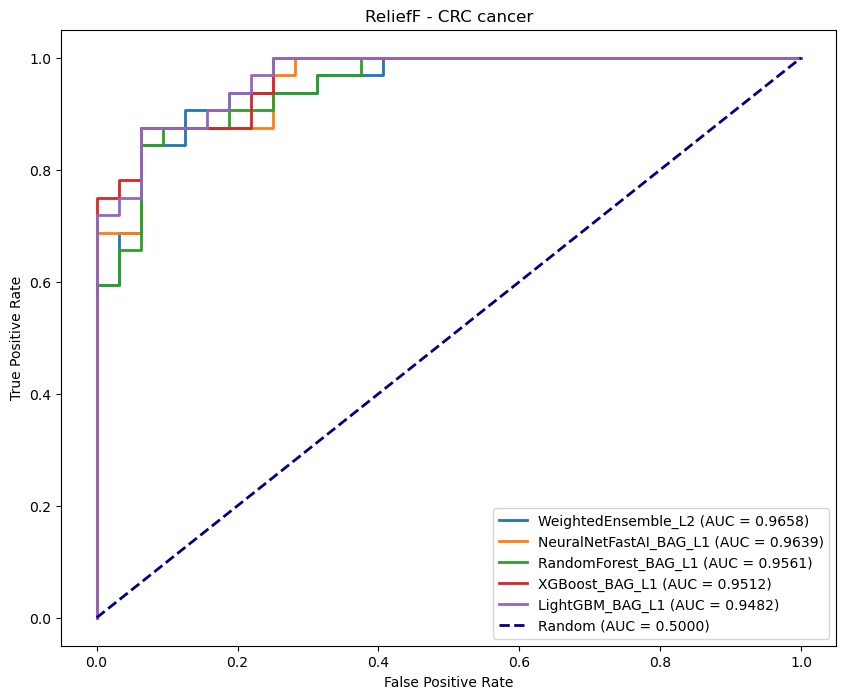

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_ReliefF(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ReliefF - CRC cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/ReliefF'
data = ReliefFdata 
plot_roc_curves_ReliefF(data, model_dir)


### Binomial

In [10]:
# 加载数据集
file_path = '../Binomial/CRC_sample_BinomialSorted_selected133.csv'
Binomialdata = pd.read_csv(file_path)

# 数据存储目录
output_dir = "../all_biomaker_detection/"
os.makedirs(output_dir, exist_ok=True)

In [11]:
Binomialdata

,class,TMD_98,TMD_122,TMD_392,TMD_64,TMD_101,TMD_112,TMD_339,TMD_73,TMD_269,...,TMD_434,GWMD_chr2_147,GWMD_chr7_79,MOTIF_END_CAAG,MOTIF_END_CAGT,TMD_35,TMD_57,TMD_115,TMD_153,TMD_318
0,1,0.245902,0.055556,0.032787,0.080808,0.022222,0.486486,0.182186,0.000000,0.237705,...,0.179348,0.841537,0.757800,0.006592,0.005469,0.113636,0.017544,0.086598,0.012821,0.107383
1,1,0.000000,0.013333,0.000000,0.050403,0.052381,0.000000,0.062057,0.078431,0.235294,...,0.132867,0.861981,0.820746,0.006611,0.005462,0.036885,0.053356,0.042813,0.017442,0.086957
2,1,0.034483,0.473684,0.294118,0.097973,0.034730,0.228070,0.019108,0.254902,0.437500,...,0.143443,0.849288,0.734885,0.006417,0.005507,0.200993,0.126667,0.134100,0.000000,0.114286
3,1,0.027027,0.000000,0.011765,0.024943,0.005874,0.049587,0.010135,0.100000,0.000000,...,0.067308,0.877376,0.826193,0.006518,0.005505,0.032154,0.012712,0.056931,0.006410,0.031579
4,1,0.000000,0.000000,0.000000,0.002439,0.053114,0.000000,0.000000,0.030000,0.000000,...,0.011940,0.865108,0.834935,0.006297,0.005530,0.000000,0.016556,0.029536,0.000000,0.007463
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
313,0,0.000000,0.000000,0.000000,0.026217,0.008904,0.005464,0.013084,0.002146,0.047619,...,0.021077,0.892491,0.859555,0.006362,0.005642,0.003185,0.019711,0.035857,0.053333,0.084095
314,0,0.000000,0.018868,0.000000,0.021097,0.004107,0.000000,0.004184,0.000000,0.000000,...,0.045455,0.872211,0.857762,0.006294,0.005568,0.016129,0.006565,0.106667,0.000000,0.044776
315,0,0.000000,0.000000,0.000000,0.055556,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.893816,0.834459,0.006068,0.005450,0.000000,0.016393,0.035714,0.000000,0.000000
316,0,0.000000,0.003012,0.009195,0.005994,0.015041,0.000000,0.010769,0.004587,0.013761,...,0.024900,0.879792,0.831420,0.006194,0.005584,0.025228,0.011741,0.032727,0.007576,0.022631


In [20]:
# 准备训练和测试集函数
def prepare_train_test_Binomial(data, cancer_type, output_dir):

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    # 设置模型保存路径
    model_path = os.path.join(output_dir, f"Model_{cancer_type}/Binomial/")
    os.makedirs(model_path, exist_ok=True)

    # 训练 AutoGluon 模型
    predictor = TabularPredictor(label='class', eval_metric='roc_auc', path=model_path).fit(
        train_data=train_data,
        presets='best_quality',
        hyperparameters={'XGB': {}, 'RF': {'criterion': 'gini'}, 'GBM': {}, 'FASTAI': {}, 'ENS_WEIGHTED': {}},
        # num_bag_folds=5
    )

    # predictor=TabularPredictor.load(f".\pancancer_detection\Model_{cancer_type}/")

    # 查看模型排行榜
    leaderboard = predictor.leaderboard(test_data, extra_metrics=['accuracy', 'balanced_accuracy', 'mcc', 'f1', 'precision', 'recall', 'roc_auc'])
    return leaderboard

In [21]:
CRC_leaderboard_Binomial = prepare_train_test_Binomial(Binomialdata, "CRC cancer", output_dir)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.1.1
Python Version:     3.12.9
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #53~22.04.1-Ubuntu SMP PREEMPT_DYNAMIC Wed Jan 15 19:18:46 UTC 2
CPU Count:          48
Memory Avail:       174.07 GB / 251.54 GB (69.2%)
Disk Space Avail:   8944.38 GB / 14784.53 GB (60.5%)
Presets specified: ['best_quality']
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` value. Copies of AutoGluon will be fit on subsets of the data. Then holdout validation data is u

In [22]:
CRC_leaderboard_Binomial.to_csv("CRC_leaderboard_Binomial.csv", index=False)
CRC_leaderboard_Binomial

,model,score_test,accuracy,balanced_accuracy,mcc,f1,precision,recall,roc_auc,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,NeuralNetFastAI_BAG_L1,0.948242,0.859375,0.859375,0.719101,0.861538,0.848485,0.87500,0.948242,0.896956,roc_auc,1.007093,0.185846,15.917170,1.007093,0.185846,15.917170,1,True,3
1,LightGBM_BAG_L1,0.947266,0.843750,0.843750,0.692935,0.833333,0.892857,0.78125,0.947266,0.924360,roc_auc,0.198277,0.010890,0.663894,0.198277,0.010890,0.663894,1,True,1
2,XGBoost_BAG_L1,0.947266,0.828125,0.828125,0.659153,0.819672,0.862069,0.78125,0.947266,0.924298,roc_auc,0.293096,0.057887,1.596996,0.293096,0.057887,1.596996,1,True,4
3,WeightedEnsemble_L2,0.945312,0.843750,0.843750,0.688847,0.838710,0.866667,0.81250,0.945312,0.932110,roc_auc,1.540508,0.361735,19.453545,0.002809,0.000426,0.028802,2,True,5
4,RandomForest_BAG_L1,0.942871,0.828125,0.828125,0.664411,0.813559,0.888889,0.75000,0.942871,0.916889,roc_auc,0.039234,0.106686,1.246682,0.039234,0.106686,1.246682,1,True,2


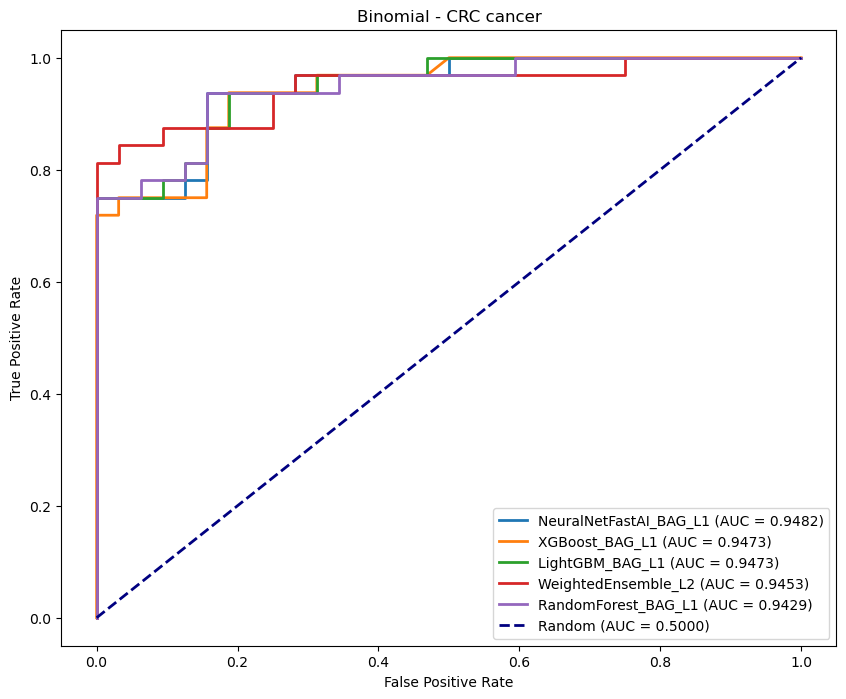

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import train_test_split

# 加载模型并绘制 ROC 曲线
def plot_roc_curves_Binomial(data, model_dir):
    # 加载整个 predictor 对象
    Fscore_predictor = TabularPredictor.load(model_dir)

    # 定义你想加载的模型名称
    models = ['XGBoost_BAG_L1', 'RandomForest_BAG_L1', 'LightGBM_BAG_L1', 'NeuralNetFastAI_BAG_L1', 'WeightedEnsemble_L2']
    
    # 用于存储每个模型和对应的 AUC 值
    auc_scores = []
    
    plt.figure(figsize=(10, 8))

    # 分层采样：拆分训练集和测试集，确保类别比例一致
    train_data, test_data = train_test_split(
        data, test_size=0.2, random_state=42, stratify=data['class']
    )

    y_true = test_data['class']  # 真实标签
    
    for model_name in models:
        # 加载每个模型
        model = Fscore_predictor._trainer.load_model(model_name)

        # 获取模型的预测概率
        y_prob = model.predict_proba(test_data)  # 获取每个样本的预测概率（正类的概率）

        # 计算 ROC 曲线的数据
        fpr, tpr, thresholds = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)

        # 将模型和 AUC 值存储到列表中
        auc_scores.append((model_name, roc_auc))

        # 绘制 ROC 曲线
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.4f})')

    # 按照 AUC 值从大到小排序
    auc_scores.append(('Random', 0.5))
    auc_scores.sort(key=lambda x: x[1], reverse=True)

    # 绘制随机猜测线
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label="Random (AUC = 0.5)")

    # 配置图表
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Binomial - CRC cancer')

    # 使用排序后的 AUC 值生成图例
    sorted_labels = [f'{model_name} (AUC = {roc_auc:.4f})' for model_name, roc_auc in auc_scores]
    plt.legend(sorted_labels, loc='lower right')

    plt.savefig(f"{model_dir}", dpi=300)
    plt.show()

model_dir = '/home/xwluo/cfDNA/elife/all_biomaker_detection/Model_CRC cancer/Binomial'
data = Binomialdata 
plot_roc_curves_Binomial(data, model_dir)


### biomaker分析

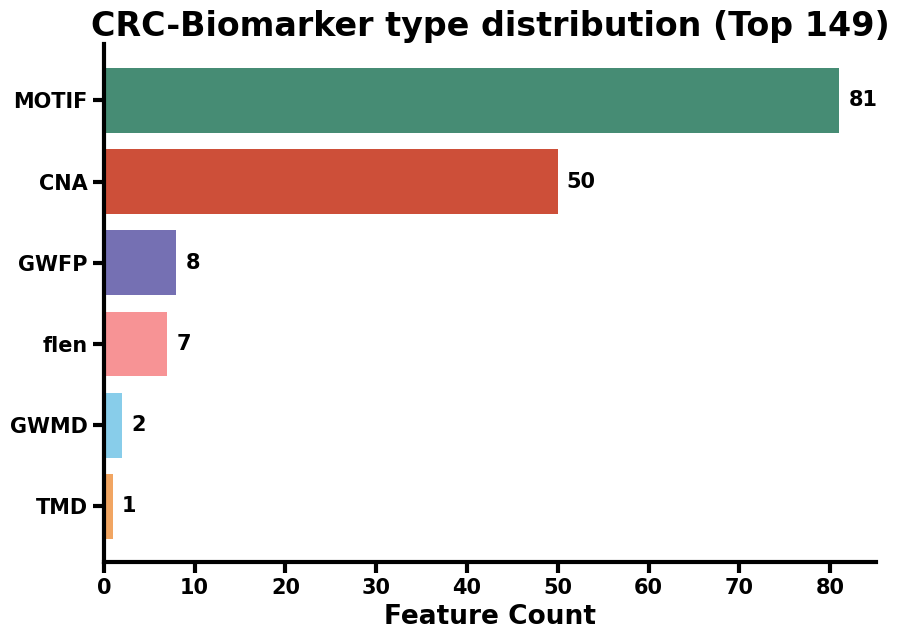

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取数据
file_path = '/home/xwluo/cfDNA/elife/Fscore/CRC_feature_importance.csv'
df = pd.read_csv(file_path, sep='\t', header=None, names=['Index', 'Marker', 'Value'])
df = df.head(149)

# 分类函数
def classify_marker(marker):
    if "GWMD" in marker:
        return "GWMD"
    elif "TMD" in marker:
        return "TMD"
    elif "GWFP" in marker:
        return "GWFP"
    elif "flen" in marker:
        return "flen"
    elif "MOTIF" in marker:
        return "MOTIF"
    elif "CNA" in marker:
        return "CNA"
    else:
        return "Other"

df['Type'] = df['Marker'].apply(classify_marker)
type_counts = df['Type'].value_counts().sort_values(ascending=True)

# 手动设置每类颜色（可根据需要修改）
custom_colors = {
    'TMD': '#f1a562',
    'GWMD': '#88cdea',
    'GWFP': '#7570b3',
    'flen': '#f79395',
    'MOTIF': '#468c74',
    'CNA': '#cd4f39',
    'Other': '#a6761d'
}

# 绘制条形图
fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(type_counts.index, type_counts.values,
            color=[custom_colors.get(t, 'black') for t in type_counts.index])

# 添加文本标签
for bar in bars:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f'{int(bar.get_width())}', va='center', fontsize=15, fontweight='bold')

# 轴设置
ax.set_xlabel("Feature Count", fontsize=19, fontweight='bold')
# ax.set_ylabel("Biomarker Type", fontsize=12)
ax.set_title("CRC-Biomarker type distribution (Top 149)", fontsize=24, fontweight='bold')

# 去掉网格线，保留边框
ax.grid(False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.yticks(fontweight='bold')
ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

plt.tight_layout()
plt.savefig("CRC-Fscore-Barplot-BiomarkerTypes_NoGrid.png", dpi=300)
plt.show()
